# Goal

Here, I will go over a few more settings in `make_image` that you can adjust.

# Imports

In [1]:
import sys
sys.path.append("..") #Point this to where the ensor.py file is located
from ensor import *

# Code

### Part 1: Open a fits file and load the bands you want to visualize
You might need to customize this to fit your own image. Just make sure each band is in nanomaggies (https://www.sdss3.org/dr8/algorithms/magnitudes.php). If your inputs are not in nanomaggies, this code comes with convenient functions that can help you convert units: `njy_to_nanomaggy`, `nanomaggy_to_njy`, `nanomaggy_to_mag`, `mag_to_nanomaggy`. In principle, this code should work with any linear flux units, but the default options for the parameters used in the various scaling/stretch functions might then need some more fine-tuning. 

We are also assuming that the images are already aligned etc. 


In [2]:
#Opening a fits file with gri bands. 
images_dir = '../data/'

fileloc = f'{images_dir}/Legacy/zoom_in.fits'

hdul = fits.open(fileloc)

g = hdul[0].data[0] #Units need to be in nanomaggy!
r = hdul[0].data[1]
z = hdul[0].data[2]

In [3]:
# We are keeping the imgs, bands, and weights constant throughout this section for simplicity.

imgs = [g,r,z]
bands = ['g','r','z']

weights = dict(
    g = (0, 0, 6.0), #r, g, b
    r = (0, 3.4, 0),
    z = (2.2, 0, 0),
)

### Part 2: offset

The dark empty sky in all astronomical images is centered around flux = 0 with a certain spread. Usually this does not affect images that much. But sometimes you'll notice too much noise/grains in the images. You can then either subtract this offset away, or add an offset with a similar spread to the entire image, so that the entire Gaussian is bumped above zero. Both approaches could work, but which you use depends on how you want to use the resultant images. In my experience, doing the former (i.e., subtracting the offset away), makes the background seem darker, but you might loose some of the very faintest structures as well. If you do the latter (i.e., adding the offset as a baseline), you keep the faintest structure while also removing some of the granularity, though the image as a whole might look a bit greyer. 

You can do either by adding the `offset` argument in `make_image`. 

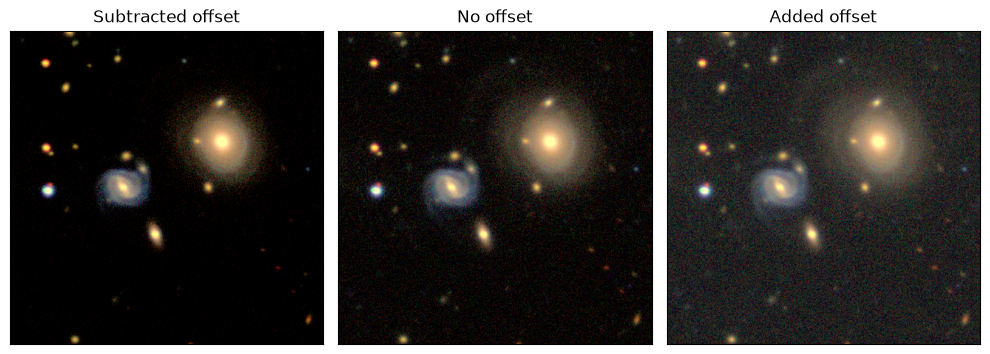

In [27]:
plt.figure(figsize = (10,5))

plt.subplot(1,3,1)
rgb = make_image(imgs, bands, weights, func = asinh, offset = -0.03)
plot_image(rgb, ax = plt.gca())
plt.title('Subtracted offset')

plt.subplot(1,3,2)
rgb = make_image(imgs, bands, weights, func = asinh, offset = 0.0)
plot_image(rgb, ax = plt.gca())
plt.title('No offset')

plt.subplot(1,3,3)
rgb = make_image(imgs, bands, weights, func = asinh, offset = +0.03)
plot_image(rgb, ax = plt.gca())
plt.title('Added offset')

plt.tight_layout()
plt.show()

The offset was a bit exaggerated to show the effects. The middle plot shows the Legacy image without any offset. In the leftmost plot, we subtracted away an offset. You'll notice the sky is darker, but we also inadvertently removed some of the fainter regions. In the rightmost plot, we instead added an offset. The whole sky looks a bit greyer, but perhaps some fainter parts of the spiral arms pop more as well.

This is up to personal preference, but I tend to prefer adding the offset, as opposed to subtracting it away. 

This package comes with a convenient function to estimate the noise properties:

In [28]:
estimate_noise(imgs)

np.float32(0.0055378973)

which you can use as an offset. Though the input offset should be scaled by the weight first. E.g., if noise = 0.005, and the weight is around 5, then the equivalent offset is 0.005*5 = 0.03.

### Part 3: apply_lupton

There are two methods to actually create an rgb image from different greyscale images. The most intuitive way would be to scale each band independently by the scaling/stretch function, and put them into their corresponding rgb channels. However, Lupton+2004 (https://arxiv.org/abs/astro-ph/0312483) described a slightly alternative approach that retains the colors of all objects, even in saturated objects. Do read Lupton+2004 for more details. By default, we use the approach presented in Lupton+2004, but you can disable this behaviour and force the slightly more simplistic approach described above by setting `apply_lupton = False`. However, I strongly advise to keep this settings to its default True value. In general, images will look more colorful when apply_lupton = True.


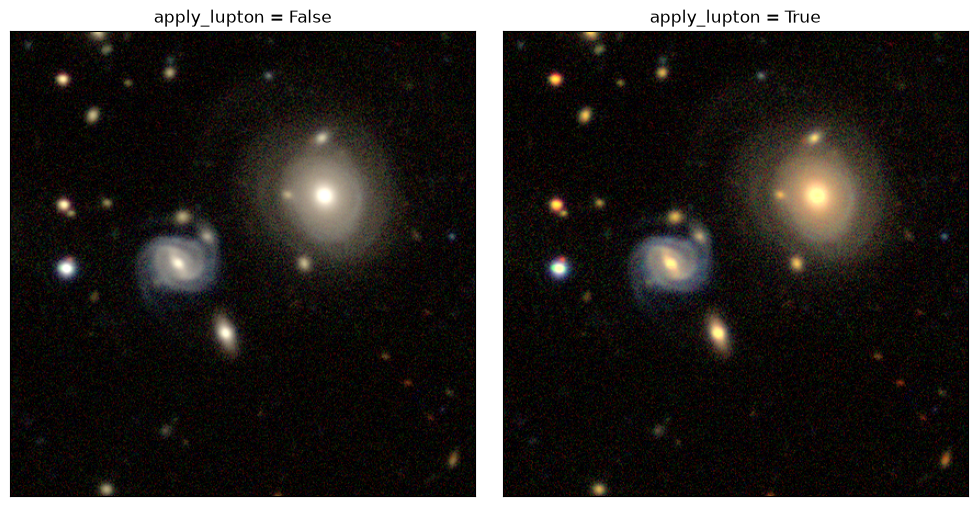

In [31]:
plt.figure(figsize = (10,5))

plt.subplot(1,2,1)
rgb = make_image(imgs, bands, weights, func = asinh, apply_lupton = False)
plot_image(rgb, ax = plt.gca())
plt.title('apply_lupton = False')

plt.subplot(1,2,2)
rgb = make_image(imgs, bands, weights, func = asinh, apply_lupton = True)
plot_image(rgb, ax = plt.gca())
plt.title('apply_lupton = True')

plt.tight_layout()
plt.show()